# 04. Paper: TabPFN (1) PFN 복습과 아키텍처

논문: Hollmann, Müller, Eggensperger, Hutter, *TabPFN: A Transformer That Solves Small Tabular Classification Problems in a Second* (ICLR 2023), [arXiv:2207.01848](https://arxiv.org/abs/2207.01848).

[`01_pfn`](../01_pfn/02_pfn_paper_walkthrough.ipynb)에서 다룬 PFN을 실제 표 데이터 분류에 쓸 수 있게 확장한 논문입니다. 원 PFN 논문도 표 데이터 실험을 했지만 학습 행 30개짜리 균형 잡힌 이진 분류까지였습니다. TabPFN은 SCM prior와 BNN prior를 섞은 넓은 prior로 Transformer 하나를 학습해서, 학습 행 1,000개, feature 100개, 클래스 10개까지의 데이터셋을 forward pass 한 번으로 분류합니다. 데이터셋마다 하는 학습도, 하이퍼파라미터 튜닝도 없습니다.

SCM과 BNN 자체는 [`01_scm_primer`](01_scm_primer.ipynb), [`02_random_scm_datasets`](02_random_scm_datasets.ipynb), [`03_bnn_primer`](03_bnn_primer.ipynb)에서 다뤘습니다. 논문 내용을 순서대로 정리하고, 재현에 쓴 TabPFN v1 코드(`src/minipfn/recipes/tabpfn_v1.py`와 그 recipe가 묶는 부품 `priors/prior_bag.py`·`models/row_transformer.py`·`inference/rotation_ensemble.py` 등)로 각 부분을 확인합니다. 논문 규모로 학습해 Table 1을 재현한 결과는 [Hub 모델 카드](../../hub/minipfn-tabpfn-v1/README.md)에 있습니다.

이 논문은 노트북 두 개로 나눠 봅니다. [04 PFN 복습과 아키텍처](04_tabpfn_paper_architecture.ipynb)(2·3절, 부록 E)와 [05 표 데이터를 위한 prior](05_tabpfn_paper_prior.ipynb)(4절, 부록 C)입니다.

이 노트북에서 다루는 흐름:

1. PFN 복습 (2절)
2. 아키텍처 변경 (3절, 부록 E)
3. 정리

## `minipfn` 불러오기

`01_pfn`과 같은 방식입니다. 이 노트북은 `notebooks/02_tabpfn/` 아래에 있으므로 저장소 루트는 두 단계 위입니다.

In [1]:
try:
    import minipfn
except ImportError:
    import sys
    from pathlib import Path

    sys.path.insert(0, str(Path.cwd().parents[1] / "src"))
    import minipfn

In [2]:
import itertools
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torch import nn

from minipfn import build_attention_mask, set_seed
from minipfn.models.row_transformer import RowTransformer
from minipfn.recipes import tabpfn_v1 as spec

set_seed(0)  # 재현성을 위해 난수 시드를 고정한다.

## 1. PFN 복습 — 2절

TabPFN은 PFN의 학습 방식을 그대로 씁니다. prior에서 합성 데이터셋을 뽑고, 일부 행의 정답을 가린 뒤, 나머지 행을 보고 가린 정답을 맞히도록 Transformer를 학습합니다. 논문 2절의 두 식도 [`01_pfn` walkthrough](../01_pfn/02_pfn_paper_walkthrough.ipynb)와 같습니다.

$$
p(y \mid x, D) \;\propto\; \int_{\Phi} p(y \mid x, \phi)\; p(D \mid \phi)\; p(\phi)\; d\phi \tag{1}
$$

$$
\mathcal{L}_{PFN} \;=\; \mathbb{E}_{(\{(x_{test},\, y_{test})\} \,\cup\, D_{train}) \sim p(D)} \big[ -\log q_\theta(y_{test} \mid x_{test}, D_{train}) \big] \tag{2}
$$

$\phi$는 데이터를 만드는 메커니즘 하나입니다. TabPFN에서는 SCM 하나 또는 BNN 하나입니다. 식 (2)의 손실을 줄이면 $q_\theta$가 식 (1)의 PPD에 가까워진다는 것은 원 논문이 보였습니다(`01_pfn` walkthrough 3절). TabPFN 논문의 새로운 점은 이 틀이 아니라, 표 데이터에 맞춘 prior(4절)와 그것을 크게 학습하는 방법(3절)입니다.

![TabPFN Figure 1](images/tabpfn_fig1.png)

*그림: 논문 Figure 1 (Hollmann et al. 2023, [arXiv:2207.01848](https://arxiv.org/abs/2207.01848)). (a) prior-fitting은 한 번만 오프라인으로 하고, 실제 데이터셋에는 forward pass 한 번만 합니다. (b) 학습 행 3개는 서로 attend하고, 테스트 행 $x_4, x_5$는 학습 행에만 attend합니다.*

표 데이터에서 "데이터셋 하나"는 아래 같은 표입니다. 과일 가게에서 무게와 당도로 사과(0)와 배(1)를 구분한다고 해 봅니다. 정답을 아는 학습 행 4개와 정답을 가린 테스트 행 2개를 함께 넣으면, 모델은 `?` 자리의 클래스 확률을 내놓습니다.

In [3]:
fruit = pd.DataFrame(
    {
        "무게(g)": [210, 190, 320, 290, 200, 310],
        "당도(brix)": [13.5, 14.0, 11.0, 11.5, 13.0, 12.0],
        "y": ["0 (사과)", "0 (사과)", "1 (배)", "1 (배)", "?", "?"],
        "역할": ["학습"] * 4 + ["테스트"] * 2,
    }
)
display(fruit)

,무게(g),당도(brix),y,역할
0,210,13.5,0 (사과),학습
1,190,14.0,0 (사과),학습
2,320,11.0,1 (배),학습
3,290,11.5,1 (배),학습
4,200,13.0,?,테스트
5,310,12.0,?,테스트


원 PFN 논문(Müller et al. 2022)도 이런 표 데이터로 실험했습니다. TabPFN이 무엇을 바꿨는지는 부록 C.2.6에 정리되어 있습니다.

| | 원 PFN의 표 데이터 실험 | TabPFN | 다루는 곳 |
|---|---|---|---|
| 학습 행 수 | 30 | 1,000 | |
| feature 수 | 60 | 100 (0으로 채움) | 2.4절 |
| 클래스 | 균형 잡힌 이진 분류 | 최대 10개, 불균형 포함 | [05](05_tabpfn_paper_prior.ipynb) 4절 |
| prior | BNN | SCM + BNN | [05](05_tabpfn_paper_prior.ipynb) 2절, 3절 |
| attention | 모든 행 쌍 $(n+m)^2$ | $n^2 + n \cdot m$ | 2.2절 |
| 전처리 | 없음 | 이상치 누르기, 추론 때 power transform | 2.5절, [05](05_tabpfn_paper_prior.ipynb) 5절 |
| 앙상블 | 없음 | feature 열·클래스 번호 회전, power transform 유무 | 2.5절 |

## 2. 아키텍처 변경 — 3절, 부록 E

모델은 원 PFN과 같은 Transformer encoder입니다. 논문 3절은 두 가지만 바꿨다고 말합니다. attention mask를 바꿔 추론을 빠르게 했고, feature 수가 다른 데이터셋을 0으로 채워 한 모델에 넣었습니다. 여기에 추론 때 쓰는 앙상블과 모델 크기까지 차례로 봅니다.

### 2.1 행 하나가 토큰 하나

Transformer에 들어가는 토큰은 표의 행입니다. 학습 행은 feature 벡터 $x$의 임베딩과 정답 $y$의 임베딩을 더해 토큰 하나로 만들고, 테스트 행은 $x$의 임베딩만 씁니다. `RowTransformer.forward`에서 해당 부분은 다음과 같습니다.

```python
h = self.x_encoder(x)                                  # 모든 행: Linear(feature 100개 → 512)
y_emb = self.y_encoder(y_train)                        # 학습 행: 클래스 번호를 실수 하나로 보고 Linear(1 → 512)
h = torch.cat([h[:, :n_train] + y_emb, h[:, n_train:]], dim=1)  # 학습 행에만 y 임베딩을 더한다
```

먼저 행 하나가 토큰이 되는 과정을 숫자로 따라가 봅니다. 숫자가 다 보이도록 임베딩 크기를 512 대신 4로 줄인 작은 모델을 쓰고, 위 과일 표에서 0번 행(사과, 학습), 2번 행(배, 학습), 4번 행(테스트) 세 개를 넣습니다.

모델에 넣기 전에 feature를 학습 행 4개의 평균과 표준편차로 표준화합니다. 추론 때 전처리가 맨 먼저 하는 일과 같습니다(`rotation_ensemble._Preprocessor`). 표준화하지 않으면 무게(약 200~300)가 당도(약 11~14)보다 훨씬 커서 임베딩을 무게가 거의 다 정합니다.

In [4]:
fruit_x = torch.tensor(fruit[["무게(g)", "당도(brix)"]].values, dtype=torch.float64)

# 학습 행(0~3번) 4개의 평균과 표준편차로 모든 행을 표준화한다
mean = fruit_x[:4].mean(dim=0)
std = fruit_x[:4].std(dim=0)
fruit_z = (fruit_x - mean) / std

display(
    pd.DataFrame(
        {
            "무게(g)": fruit["무게(g)"],
            "당도(brix)": fruit["당도(brix)"],
            "무게 (표준화)": fruit_z[:, 0].numpy(),
            "당도 (표준화)": fruit_z[:, 1].numpy(),
            "역할": fruit["역할"],
        }
    ).round(2)
)

,무게(g),당도(brix),무게 (표준화),당도 (표준화),역할
0,210,13.5,-0.68,0.68,학습
1,190,14.0,-1.00,1.02,학습
2,320,11.0,1.08,-1.02,학습
3,290,11.5,0.60,-0.68,학습
4,200,13.0,-0.84,0.34,테스트
5,310,12.0,0.92,-0.34,테스트


두 인코더는 모두 Linear 층 하나입니다. `x_encoder`는 feature 2개를 임베딩 4칸으로, `y_encoder`는 클래스 번호 하나를 임베딩 4칸으로 바꿉니다. 아래 가중치는 학습 전의 무작위 초기값입니다.

In [5]:
torch.manual_seed(0)
# 임베딩 크기 4짜리 작은 모델 (실제 TabPFN은 512)
demo = RowTransformer(num_features=2, n_out=10, emsize=4, nhead=2, nhid=8, nlayers=1).double().eval()

# x_encoder = Linear(feature 2개 → 임베딩 4칸): 가중치 W_x (4×2)와 bias b_x (4칸)
W_x = demo.x_encoder.weight.detach()
b_x = demo.x_encoder.bias.detach()

# y_encoder = Linear(1 → 임베딩 4칸): 가중치 w_y (4칸)와 bias b_y (4칸)
w_y = demo.y_encoder.weight.detach()[:, 0]
b_y = demo.y_encoder.bias.detach()

dims = [f"임베딩 {i}" for i in range(4)]
display(
    pd.DataFrame(
        {
            "W_x (무게 열)": W_x[:, 0].numpy(),
            "W_x (당도 열)": W_x[:, 1].numpy(),
            "b_x": b_x.numpy(),
            "w_y": w_y.numpy(),
            "b_y": b_y.numpy(),
        },
        index=dims,
    ).round(3)
)

,W_x (무게 열),W_x (당도 열),b_x,w_y,b_y
임베딩 0,-0.005,0.379,-0.063,-0.955,0.395
임베딩 1,-0.582,-0.520,0.187,-0.662,0.600
임베딩 2,-0.272,0.190,-0.214,-0.412,-0.678
임베딩 3,-0.014,0.561,-0.139,0.037,-0.435


x 임베딩은 $W_x x + b_x$입니다. 임베딩 칸마다 표준화한 무게와 당도에 그 칸의 가중치를 곱해 더하고 bias를 더합니다. 0번 행의 임베딩 0번 칸 하나만 손으로 계산해 `x_encoder`의 결과와 비교합니다.

In [6]:
z_row0 = fruit_z[0]  # 0번 행 (사과, 학습), 표준화한 값

with torch.no_grad():
    weight_term = W_x[0, 0] * z_row0[0]  # 무게 몫
    sugar_term = W_x[0, 1] * z_row0[1]  # 당도 몫
    by_hand = weight_term + sugar_term + b_x[0]
    by_layer = demo.x_encoder(z_row0)[0]

print(f"무게 몫: {W_x[0, 0]:.3f} × {z_row0[0]:.3f} = {weight_term:.3f}")
print(f"당도 몫: {W_x[0, 1]:.3f} × {z_row0[1]:.3f} = {sugar_term:.3f}")
print(f"bias:    {b_x[0]:.3f}")
print(f"합:      {by_hand:.3f}")
print(f"x_encoder로 계산한 값: {by_layer:.3f}")

무게 몫: -0.005 × -0.681 = 0.004
당도 몫: 0.379 × 0.679 = 0.258
bias:    -0.063
합:      0.199
x_encoder로 계산한 값: 0.199


나머지 세 칸도 같은 계산입니다. 이제 세 행을 토큰으로 만듭니다. 학습 행은 x 임베딩에 y 임베딩 $w_y y + b_y$를 더해 토큰을 만들고, 테스트 행은 정답을 모르므로 x 임베딩이 그대로 토큰이 됩니다.

In [7]:
rows = {
    "0번 행 (사과, 학습)": (fruit_z[0], 0.0),
    "2번 행 (배, 학습)": (fruit_z[2], 1.0),
    "4번 행 (테스트)": (fruit_z[4], None),  # 정답을 모른다
}

with torch.no_grad():
    for name, (z, y) in rows.items():
        # 1단계: feature 2개 → 임베딩 4칸
        x_emb = demo.x_encoder(z)
        table = {"x 임베딩": x_emb.numpy()}

        if y is None:
            # 테스트 행: x 임베딩이 그대로 토큰
            token = x_emb
        else:
            # 2단계: 클래스 번호를 실수 하나로 보고 → 임베딩 4칸
            y_emb = demo.y_encoder(torch.tensor([y], dtype=torch.float64))
            table["y 임베딩"] = y_emb.numpy()
            # 3단계: 둘을 더하면 토큰 하나
            token = x_emb + y_emb

        table["토큰"] = token.numpy()
        print(name)
        display(pd.DataFrame(table, index=dims).round(3))

0번 행 (사과, 학습)


,x 임베딩,y 임베딩,토큰
임베딩 0,0.199,0.395,0.594
임베딩 1,0.230,0.600,0.830
임베딩 2,0.101,-0.678,-0.577
임베딩 3,0.251,-0.435,-0.184


2번 행 (배, 학습)


,x 임베딩,y 임베딩,토큰
임베딩 0,-0.455,-0.560,-1.015
임베딩 1,0.088,-0.062,0.025
임베딩 2,-0.702,-1.090,-1.792
임베딩 3,-0.725,-0.398,-1.124


4번 행 (테스트)


,x 임베딩,토큰
임베딩 0,0.071,0.071
임베딩 1,0.500,0.500
임베딩 2,0.080,0.080
임베딩 3,0.063,0.063


0번 행은 클래스 0이라 $w_y \times 0 = 0$이 되어 y 임베딩이 $b_y$ 그대로입니다. 2번 행은 클래스 1이라 y 임베딩이 $w_y + b_y$입니다. 같은 클래스의 학습 행에는 같은 벡터가 더해지므로, 토큰 안에 그 행의 정답이 섞여 들어갑니다.

테스트 행 토큰에는 정답 몫이 없습니다. Transformer 층에서 테스트 행 토큰이 학습 행 토큰에 attend하면서 이 자리를 채우고(2.2절), 마지막에 decoder가 테스트 행 토큰을 클래스 logit으로 바꿉니다.

이제 과일 표 전체를 작은 모델에 넣어 shape을 따라가 봅니다. 맨 앞 차원은 데이터셋 수(batch)입니다. 학습하지 않은 모델이라 확률 값 자체에는 의미가 없습니다.

In [8]:
# 과일 표를 텐서로: 맨 앞 차원 1 = 데이터셋 1개
x_train = torch.tensor([[210, 13.5], [190, 14.0], [320, 11.0], [290, 11.5]]).unsqueeze(0)
y_train = torch.tensor([0, 0, 1, 1]).float().unsqueeze(0)
x_test = torch.tensor([[200, 13.0], [310, 12.0]]).unsqueeze(0)

# feature 2개, 출력 logit 10개(최대 클래스 수)인 작은 모델
tiny = RowTransformer(num_features=2, n_out=10, emsize=8, nhead=2, nhid=16, nlayers=2).eval()
with torch.no_grad():
    logits = tiny(x_train, y_train, x_test)

n_classes = 2
proba = torch.softmax(logits[..., :n_classes], dim=-1)  # 실제 클래스 수만큼만 잘라 softmax

print("x_train:", tuple(x_train.shape), " (데이터셋, 학습 행, feature)")
print("y_train:", tuple(y_train.shape), "    (데이터셋, 학습 행)")
print("x_test: ", tuple(x_test.shape), " (데이터셋, 테스트 행, feature)")
print("logits: ", tuple(logits.shape), "(데이터셋, 테스트 행, 최대 클래스 수)")
print("proba:  ", tuple(proba.shape), " (데이터셋, 테스트 행, 실제 클래스 수)")

x_train: (1, 4, 2)  (데이터셋, 학습 행, feature)
y_train: (1, 4)     (데이터셋, 학습 행)
x_test:  (1, 2, 2)  (데이터셋, 테스트 행, feature)
logits:  (1, 2, 10) (데이터셋, 테스트 행, 최대 클래스 수)
proba:   (1, 2, 2)  (데이터셋, 테스트 행, 실제 클래스 수)


출력은 항상 logit 10개이고, 클래스가 2개인 데이터셋이면 앞의 2개만 씁니다. 학습할 때도 테스트 행의 logit에 cross-entropy를 겁니다(`losses.classification_loss`).

### 2.2 attention mask — 부록 E.2

원 PFN은 모든 행 쌍의 attention을 한 번에 계산하고 mask로 막았습니다. 학습 행은 학습 행에만, 테스트 행은 학습 행과 자기 자신에 attend합니다(논문 식 3). TabPFN은 테스트 행이 자기 자신에도 attend하지 않게 바꿨습니다(논문 식 4). 테스트 행 자신의 정보는 residual 연결로 계속 전달됩니다.

학습 행 3개, 테스트 행 2개로 두 mask를 비교합니다. 행은 attend하는 쪽, 열은 attend받는 쪽이고, 1이면 attend합니다. `build_attention_mask`는 `01_pfn` 재현에 쓴 원 PFN의 mask입니다.

In [9]:
n_train, n_test = 3, 2
names = ["train 1", "train 2", "train 3", "test 4", "test 5"]

# 원 PFN (식 3): build_attention_mask는 True = 막음이므로 뒤집는다
pfn_allowed = ~build_attention_mask(n_train, n_test)

# TabPFN (식 4): 모든 행이 학습 행 열만 본다
col = torch.arange(n_train + n_test)
tabpfn_allowed = (col < n_train).expand(n_train + n_test, -1)

print("원 PFN (식 3)")
display(pd.DataFrame(pfn_allowed.int().numpy(), index=names, columns=names))
print("TabPFN (식 4)")
display(pd.DataFrame(tabpfn_allowed.int().numpy(), index=names, columns=names))

원 PFN (식 3)


,train 1,train 2,train 3,test 4,test 5
train 1,1,1,1,0,0
train 2,1,1,1,0,0
train 3,1,1,1,0,0
test 4,1,1,1,1,0
test 5,1,1,1,0,1


TabPFN (식 4)


,train 1,train 2,train 3,test 4,test 5
train 1,1,1,1,0,0
train 2,1,1,1,0,0
train 3,1,1,1,0,0
test 4,1,1,1,0,0
test 5,1,1,1,0,0


식 4에서는 모든 행이 학습 행 열만 봅니다. 그래서 TabPFN 구현은 mask를 쓰지 않고 attention을 두 번 나눠 계산합니다(`TabPFNLayer._attend`). 학습 행끼리의 self-attention 한 번, 테스트 행에서 학습 행으로 가는 cross-attention 한 번이고, 두 번 모두 같은 가중치를 씁니다. 계산하는 attention 점수가 $(n+m)^2$개에서 $n^2 + n \cdot m$개로 줄어듭니다.

In [10]:
rows = []
for n, m in [(1000, 1000), (1000, 100), (100, 1000)]:
    full = (n + m) ** 2  # 원 PFN: 모든 행 쌍
    split = n**2 + n * m  # TabPFN: 학습↔학습 + 테스트→학습
    rows.append(
        {
            "학습 행 n": n,
            "테스트 행 m": m,
            "(n+m)²": full,
            "n²+n·m": split,
            "비율": round(split / full, 3),
        }
    )
display(pd.DataFrame(rows))

,학습 행 n,테스트 행 m,(n+m)²,n²+n·m,비율
0,1000,1000,4000000,2000000,0.500
1,1000,100,1210000,1100000,0.909
2,100,1000,1210000,110000,0.091


비율은 $n/(n+m)$입니다. 학습 행과 테스트 행이 같은 수면 절반으로 줄고, 테스트 행이 많을수록 더 많이 줄어듭니다.

### 2.3 mask가 보장하는 두 성질

이 mask와 위치 인코딩이 없다는 점 때문에 두 성질이 생깁니다.

1. 학습 행의 순서를 바꿔도 예측이 같습니다. 학습 데이터를 집합으로 다룹니다.
2. 테스트 행 하나의 예측은 다른 테스트 행과 무관합니다. 그래서 테스트 행을 한 번에 몇 개를 넣든 결과가 같습니다.

무작위 가중치 모델로 확인합니다. `RowTransformer`는 v1처럼 attention 출력과 FFN 마지막 층을 0으로 초기화합니다. 이 상태에서는 attention이 아무 일도 하지 않아 확인하는 의미가 없으므로, 모든 가중치를 무작위 값으로 바꾼 뒤 확인합니다. 비교용으로 학습 행 하나의 정답을 바꾼 경우도 함께 봅니다. 이때는 예측이 달라져야 합니다.

In [11]:
torch.manual_seed(0)
model = RowTransformer(num_features=5, n_out=3, emsize=16, nhead=2, nhid=32, nlayers=2).eval()
for p in model.parameters():
    nn.init.normal_(p, std=0.5)  # 0으로 초기화된 층도 attention이 일하도록 무작위 값으로

x_tr = torch.randn(1, 20, 5)  # 학습 행 20개
y_tr = torch.randint(0, 3, (1, 20)).float()
x_te = torch.randn(1, 6, 5)  # 테스트 행 6개

with torch.no_grad():
    base = model(x_tr, y_tr, x_te)

    # 성질 1: 학습 행 순서 바꾸기
    perm = torch.randperm(20)
    shuffled = model(x_tr[:, perm], y_tr[:, perm], x_te)

    # 성질 2: 테스트 행을 하나씩 따로 넣기
    one_by_one = [model(x_tr, y_tr, x_te[:, j : j + 1]) for j in range(6)]
    one_by_one = torch.cat(one_by_one, dim=1)

    # 비교용: 학습 행 하나의 정답만 바꾸기
    y_changed = y_tr.clone()
    y_changed[0, 0] = (y_changed[0, 0] + 1) % 3
    changed = model(x_tr, y_changed, x_te)

checks = {
    "학습 행 순서를 바꿈": shuffled,
    "테스트 행을 하나씩 넣음": one_by_one,
    "학습 행 하나의 정답을 바꿈 (비교용)": changed,
}
display(
    pd.DataFrame(
        {
            "원래 logit과의 최대 차이": {
                k: f"{(v - base).abs().max().item():.2e}" for k, v in checks.items()
            }
        }
    )
)

,원래 logit과의 최대 차이
학습 행 순서를 바꿈,4.77e-07
테스트 행을 하나씩 넣음,6.56e-07
학습 행 하나의 정답을 바꿈 (비교용),8.71e-03


앞의 두 경우는 차이가 float 반올림 오차 수준이고, 정답을 바꾼 경우만 크게 달라집니다. 학습한 모델이 아니어도 구조만으로 두 성질이 성립합니다.

### 2.4 feature 수가 다른 데이터셋 — 부록 E.2

`x_encoder`는 입력 크기가 100으로 고정된 Linear입니다. feature가 $k$개($k < 100$)인 데이터셋은 나머지 열을 0으로 채우고, 쓴 열은 $100/k$배 합니다.

작은 예로 보기 위해 최대 feature 수를 6으로 줄이고, feature 3개짜리 표를 넣어 봅니다. $6/3 = 2$배가 됩니다.

In [12]:
max_features = 6  # 실제 TabPFN은 100
small = pd.DataFrame({"f1": [0.5, -1.2, 0.7], "f2": [1.0, 0.3, -1.3], "f3": [-0.4, 0.9, -0.5]})
k = small.shape[1]

scaled = small * (max_features / k)  # 쓴 열을 6/3 = 2배
padded = scaled.copy()
for j in range(k + 1, max_features + 1):
    padded[f"f{j}"] = 0.0  # 나머지 열은 0으로 채운다

print(f"원래 표 (feature {k}개)")
display(small)
print(f"모델 입력 (열 {max_features}개, 쓴 열은 {max_features / k:g}배)")
display(padded)

원래 표 (feature 3개)


,f1,f2,f3
0,0.5,1.0,-0.4
1,-1.2,0.3,0.9
2,0.7,-1.3,-0.5


모델 입력 (열 6개, 쓴 열은 2배)


,f1,f2,f3,f4,f5,f6
0,1.0,2.0,-0.8,0.0,0.0,0.0
1,-2.4,0.6,1.8,0.0,0.0,0.0
2,1.4,-2.6,-1.0,0.0,0.0,0.0


왜 $100/k$배 할까요? 0인 열이 많을수록 행 전체 값의 크기가 작아지기 때문입니다. 표준화한 feature를 $k$개 쓰고 나머지를 0으로 채웠을 때, 100열 전체에서 $|x|$의 평균을 비교합니다.

In [13]:
rng = np.random.default_rng(0)
rows = []
for k in [1, 3, 10, 30, 100]:
    x = rng.standard_normal((1000, k))  # 표준화한 feature k개, 행 1,000개
    x_padded = np.concatenate([x, np.zeros((1000, 100 - k))], axis=1)
    x_scaled = x_padded * (100 / k)
    rows.append(
        {
            "쓴 feature k": k,
            "0으로만 채움": round(np.abs(x_padded).mean(), 3),
            "0으로 채우고 100/k배": round(np.abs(x_scaled).mean(), 3),
        }
    )
display(pd.DataFrame(rows))

,쓴 feature k,0으로만 채움,0으로 채우고 100/k배
0,1,0.008,0.777
1,3,0.024,0.811
2,10,0.080,0.799
3,30,0.240,0.801
4,100,0.797,0.797


0으로만 채우면 feature가 적을수록 입력이 작아지고, $100/k$배 하면 feature 수와 상관없이 100열 평균 크기가 같아집니다(표준정규분포의 $E|x| \approx 0.80$). 학습 때 prior 데이터에도(`TabPFNPrior.sample_group`의 4단계), 추론 때 실제 데이터에도(`rotation_ensemble._Preprocessor._finish`의 마지막 줄) 같은 변환을 합니다.

### 2.5 추론 때의 앙상블 — 3절, 부록 C.2.6

논문의 TabPFN 결과는 같은 데이터셋을 조금씩 바꿔 forward pass를 32번 한 결과의 평균입니다. 바꾸는 방법은 세 가지입니다.

1. **feature 열 번호 회전**: 열 순서를 돌립니다.
2. **클래스 번호 회전**: 클래스에 붙인 번호를 돌립니다.
3. **power transform(Yeo-Johnson) 적용 여부**: 꼬리가 긴 feature를 정규분포에 가깝게 폅니다.

앞의 두 가지는 열 순서와 클래스 번호처럼 아무렇게나 정한 것이 예측에 끼어드는 것을 줄이려는 것입니다. 학습 때도 prior 데이터의 열과 클래스 번호를 돌리므로 모델이 이 회전에 무관해지도록 배우기는 하지만, 완전히 무관하지는 않아서 앙상블이 도움이 됩니다(논문 각주 1). 세 번째는 실제 데이터를 prior 데이터와 비슷한 모양으로 바꾸려는 것입니다.

세 가지를 하나씩 보고, 마지막에 이 셋을 조합해 멤버 32개를 어떻게 고르는지 봅니다.

#### (1) feature 열 번호 회전

`x_encoder`는 열마다 다른 가중치를 곱합니다. 2.1절의 표에서 무게 열에는 `W_x (무게 열)`, 당도 열에는 `W_x (당도 열)`이 곱해졌습니다. 그래서 같은 무게라도 0번 열에 들어가느냐 1번 열에 들어가느냐에 따라 임베딩이 달라집니다. 열 순서는 데이터를 모은 사람이 정한 것일 뿐이므로, 여러 순서로 넣어 보고 평균합니다.

"$s$칸 돌린다"는 앞의 열 $s$개를 맨 뒤로 보내는 것입니다. 논문 각주 10의 예 $[x_1, x_2, x_3, x_4] \to [x_3, x_4, x_1, x_2]$는 2칸 돌린 것입니다. feature가 4개인 과일 표로 보면 다음과 같습니다.

In [14]:
feature_names = ["무게", "당도", "지름", "산도"]

orders = {}
for s in range(len(feature_names)):
    # s칸 돌리기: 앞의 s개 열을 맨 뒤로 보낸다
    orders[f"{s}칸 돌림"] = feature_names[s:] + feature_names[:s]

display(pd.DataFrame(orders, index=[f"모델 입력 {i}번 열" for i in range(len(feature_names))]))

,0칸 돌림,1칸 돌림,2칸 돌림,3칸 돌림
모델 입력 0번 열,무게,당도,지름,산도
모델 입력 1번 열,당도,지름,산도,무게
모델 입력 2번 열,지름,산도,무게,당도
모델 입력 3번 열,산도,무게,당도,지름


순서만 돌리므로 열끼리의 이웃 관계(무게 다음에 당도)는 유지됩니다. feature가 $k$개면 열 회전은 $k$가지입니다. 실제 구현은 `rotation_ensemble.RotationEnsembleClassifier._member_inputs`의 `torch.cat([x[:, s:], x[:, :s]])` 한 줄입니다.

#### (2) 클래스 번호 회전

클래스 번호는 사람이 아무렇게나 붙인 이름표입니다. 사과, 배, 귤을 0, 1, 2로 붙이든 2, 0, 1로 붙이든 같은 데이터셋입니다. 그런데 2.1절에서 본 것처럼 v1의 `y_encoder`는 클래스 번호를 실수 하나로 보고 $w_y y + b_y$를 계산합니다. 2.1절의 작은 모델(`demo`)로 클래스 0, 1, 2의 y 임베딩을 봅니다.

In [15]:
y_embs = {}
with torch.no_grad():
    for c in range(3):
        # 클래스 번호 c를 실수 하나로 넣는다 → w_y · c + b_y
        y_embs[f"클래스 {c}"] = demo.y_encoder(torch.tensor([float(c)], dtype=torch.float64)).numpy()

y_embs["w_y"] = w_y.numpy()
display(pd.DataFrame(y_embs, index=dims).round(3))

,클래스 0,클래스 1,클래스 2,w_y
임베딩 0,0.395,-0.560,-1.515,-0.955
임베딩 1,0.600,-0.062,-0.725,-0.662
임베딩 2,-0.678,-1.090,-1.502,-0.412
임베딩 3,-0.435,-0.398,-0.361,0.037


클래스 0의 y 임베딩은 $b_y$이고, 번호가 1 커질 때마다 $w_y$만큼 더해집니다. 모델에게 0번과 2번은 서로 다른 입력이라서, 사과에 0을 붙였느냐 2를 붙였느냐에 따라 예측이 조금 달라질 수 있습니다. 그래서 추론 때 번호를 여러 방식으로 붙여 각각 예측하고 평균합니다. "$s$칸 돌린다"는 모든 번호에 $s$를 더하고, 클래스 수 $j$를 넘으면 0부터 다시 세는 것입니다($(y + s) \bmod j$). 번호가 0 → 1 → 2 → 0으로 원을 따라 돌아서 회전이라고 부릅니다.

| 과일 | 원래 번호 | 1칸 돌림 | 2칸 돌림 |
|---|---|---|---|
| 사과 | 0 | 1 | 2 |
| 배 | 1 | 2 | 0 |
| 귤 | 2 | 0 | 1 |

돌린 번호로 넣으면 모델이 내는 확률도 돌린 번호 기준입니다. 그래서 평균하기 전에 원래 번호로 되돌려야 합니다. 1칸 돌린 경우를 따라가 봅니다. 학습 행의 정답을 1칸 돌려 넣고, 테스트 행 하나에 대해 모델이 아래 확률을 냈다고 해 봅니다(설명용으로 정한 값).

In [16]:
n_classes, shift = 3, 1
fruit_names = np.array(["사과", "배", "귤"])  # 원래 번호 0, 1, 2

# 1단계: 학습 행의 정답을 1칸 돌려서 넣는다 (0→1, 1→2, 2→0)
y_original = np.array([0, 1, 2, 2, 0])
y_rotated = (y_original + shift) % n_classes
display(
    pd.DataFrame(
        {
            "과일": fruit_names[y_original],
            "원래 정답": y_original,
            "돌린 정답 (모델 입력)": y_rotated,
        }
    )
)

# 2단계: 모델은 돌린 번호 기준으로 확률을 낸다 (설명용 값)
proba_rotated = np.array([0.1, 0.7, 0.2])

# 3단계: 원래 클래스 c는 돌린 번호 (c + 1) % 3이었으므로 그 자리의 확률을 가져온다
proba_original = np.array([proba_rotated[(c + shift) % n_classes] for c in range(n_classes)])
display(
    pd.DataFrame(
        {"돌린 번호 기준 확률": proba_rotated, "원래 번호로 되돌린 확률": proba_original},
        index=[f"클래스 {c}" for c in range(n_classes)],
    )
)

,과일,원래 정답,돌린 정답 (모델 입력)
0,사과,0,1
1,배,1,2
2,귤,2,0
3,귤,2,0
4,사과,0,1


,돌린 번호 기준 확률,원래 번호로 되돌린 확률
클래스 0,0.1,0.7
클래스 1,0.7,0.2
클래스 2,0.2,0.1


돌린 번호 1의 확률 0.7은 원래 클래스 0, 곧 사과의 확률입니다. 앙상블 멤버마다 이렇게 되돌린 다음 평균합니다. 실제 구현(`spec.TabPFNv1Classifier`)은 확률 대신 logit을 되돌려 평균한 뒤 softmax합니다. 클래스가 $j$개면 클래스 회전은 $j$가지입니다.

#### (3) power transform 적용 여부

power transform은 집값이나 소득처럼 오른쪽 꼬리가 긴 feature를 위한 것입니다. prior 데이터는 신경망 출력을 표준화한 값이라 이런 꼬리가 드물어서, 추론 때 실제 데이터를 prior 데이터와 비슷한 모양으로 바꿔 줍니다(부록 C.2.1). 멤버마다 모든 feature에 power transform을 한 것(`power_all`)과 하지 않은 것(`none`) 중 하나를 씁니다. 그래서 2가지입니다.

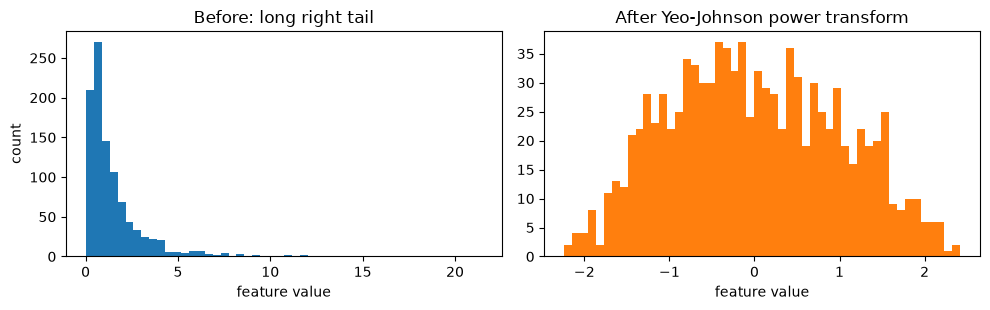

In [17]:
from sklearn.preprocessing import PowerTransformer

rng = np.random.default_rng(0)
skewed = rng.lognormal(mean=0.0, sigma=1.0, size=(1000, 1))  # 오른쪽 꼬리가 긴 feature
transformed = PowerTransformer(method="yeo-johnson", standardize=True).fit_transform(skewed)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(skewed[:, 0], bins=50, color="C0")
axes[0].set_title("Before: long right tail")
axes[1].hist(transformed[:, 0], bins=50, color="C1")
axes[1].set_title("After Yeo-Johnson power transform")
for ax in axes:
    ax.set_xlabel("feature value")
axes[0].set_ylabel("count")
plt.tight_layout()
plt.show()

#### 세 가지를 조합해 멤버 고르기

멤버 하나는 (클래스 회전, 열 회전, 변환)의 조합 하나입니다. feature가 $k$개, 클래스가 $j$개면 가능한 조합은 열 회전 $k$가지 × 클래스 회전 $j$가지 × 변환 2가지 = $2kj$개입니다. 32가 이보다 크면 $2kj$개만 씁니다.

`spec.TabPFNv1Classifier.fit`은 이 순서로 멤버를 고릅니다.

1. 열 회전 $k$가지와 클래스 회전 $j$가지를 각각 무작위 순서로 늘어놓습니다.
2. 둘을 짝지은 $kj$쌍을 다시 무작위로 섞습니다.
3. 쌍마다 `none`과 `power_all`을 붙여 $2kj$개를 만들고, 앞에서부터 32개를 씁니다.

feature 4개, 클래스 3개인 데이터셋이면 조합이 $2 \times 4 \times 3 = 24$개라 24개를 모두 씁니다.

In [18]:
k, n_classes, n_ensemble, seed = 4, 3, 32, 0

# spec.TabPFNv1Classifier.fit과 같은 순서로 멤버를 고른다
torch.manual_seed(seed)

# 1단계: 열 회전 k가지, 클래스 회전 j가지를 각각 무작위 순서로
feature_shifts = torch.randperm(k).tolist()
class_shifts = torch.randperm(n_classes).tolist()

# 2단계: (클래스 회전, 열 회전) 쌍 k·j개를 만들어 섞는다
shift_pairs = list(itertools.product(class_shifts, feature_shifts))
random.Random(seed).shuffle(shift_pairs)

# 3단계: 쌍마다 변환 2가지를 붙이고 앞에서부터 n_ensemble개
all_members = list(itertools.product(shift_pairs, ["none", "power_all"]))
members = all_members[:n_ensemble]

print(f"가능한 조합 2·k·j = {2 * k * n_classes}, 쓰는 멤버 수 = {len(members)}")
display(
    pd.DataFrame(
        [{"클래스 회전": c, "열 회전": f, "변환": t} for (c, f), t in members[:6]],
        index=[f"멤버 {i}" for i in range(6)],
    )
)

가능한 조합 2·k·j = 24, 쓰는 멤버 수 = 24


,클래스 회전,열 회전,변환
멤버 0,0,1,none
멤버 1,0,1,power_all
멤버 2,1,1,none
멤버 3,1,1,power_all
멤버 4,1,0,none
멤버 5,1,0,power_all


같은 쌍에 `none`과 `power_all`이 붙어 나오므로 멤버 0과 1은 회전이 같고 변환만 다릅니다. 각 멤버는 (1)처럼 열을 돌리고, (2)처럼 학습 행의 정답 번호를 돌리고, (3)의 변환을 한 데이터로 forward pass를 한 번 합니다. 멤버마다 logit을 원래 클래스 번호로 되돌린 뒤 평균하고 softmax한 것이 최종 예측입니다.

### 2.6 모델 크기와 학습 — 부록 E.1, E.3

| 항목 | 논문 |
|---|---|
| Transformer | 12층, 임베딩 512, FFN 1,024, head 4 |
| 파라미터 수 | 25.82M |
| 학습 | 18,000 step × batch 512 = 합성 데이터셋 9,216,000개 |
| 학습 시간 | RTX 2080 Ti 8장에서 20시간 |
| 최적화 | Adam, linear warmup + cosine, lr은 {0.001, 0.0003, 0.0001} 중 마지막 학습 loss가 가장 낮은 것 |

논문은 학습 곡선이 데이터셋 약 1,000만 개에서 평평해지고, prior가 매우 다양한 데이터셋을 만들어서 곡선이 많이 출렁였다고 적었습니다(E.3). 이 저장소는 같은 규모를 H100 8장에서 2시간 5분에 학습했습니다([Hub 모델 카드](../../hub/minipfn-tabpfn-v1/README.md)).

논문 크기로 모델을 만들어 파라미터 수를 부분별로 세어 봅니다.

In [19]:
paper_model = RowTransformer(**spec.PAPER_MODEL)  # 논문 크기 (recipes/tabpfn_v1.py)

parts = {
    "x_encoder (100 → 512)": paper_model.x_encoder,
    "y_encoder (1 → 512)": paper_model.y_encoder,
    "Transformer 층 12개": paper_model.layers,
    "decoder (512 → 1024 → 10)": paper_model.decoder,
}
counts = {name: sum(p.numel() for p in m.parameters()) for name, m in parts.items()}
counts["합계"] = paper_model.num_parameters()
display(pd.DataFrame({"파라미터 수": {k: f"{v:,}" for k, v in counts.items()}}))

,파라미터 수
x_encoder (100 → 512),"51,712"
y_encoder (1 → 512),"1,024"
Transformer 층 12개,"25,233,408"
decoder (512 → 1024 → 10),"535,562"
합계,"25,821,706"


합계 25,821,706개로 논문의 25.82M과 같습니다. 대부분이 Transformer 층에 있고, 층 하나에 attention 약 105만 개, FFN 약 105만 개입니다.

## 3. 정리

| 논문 | 핵심 | 이 저장소 코드 |
|---|---|---|
| 2절 | PFN과 같은 손실로 prior의 PPD를 근사한다 | `spec.train_tabpfn`, `losses.classification_loss` |
| 3절, E.2 | 테스트 행은 학습 행에만 attend한다 ($n^2 + n \cdot m$) | `row_transformer.RowTransformerLayer._attend` |
| E.2 | feature를 100열까지 0으로 채우고 $100/k$배 한다 | `transforms.scaling.PadFeatures`, `rotation_ensemble._Preprocessor` |
| 3절, C.2.6 | 열 회전, 클래스 회전, power transform으로 앙상블 32개 | `spec.TabPFNv1Classifier` (`rotation_ensemble.RotationEnsembleClassifier`) |
| E.1, E.3 | 12층, 임베딩 512, 25.82M 파라미터, 합성 데이터셋 약 920만 개로 학습 | `spec.PAPER_MODEL` |

다음 노트북 [05 표 데이터를 위한 prior](05_tabpfn_paper_prior.ipynb)에서는 이 모델이 학습하는 합성 데이터셋, 곧 논문 4절의 prior를 봅니다.